# Data Preprocessing OBB

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
data = df = pd.read_csv("../data/obb/2026-11-16_mmtis_zugfahrten.csv")

In [3]:
data.head()

,zugnummer,betriebstag,abfahrtzeit_soll,abfahrtzeit_ist,start_betriebsstelle,ankunftzeit_soll,ankunftzeit_ist,ziel_betriebsstelle,fahrzeit_delta
0,50,2026-11-02,2026-11-02T21:12:16+0100,2026-11-02T21:12:40+0100,OF,2026-11-02T22:05:36+0100,2026-11-02T22:06:09+0100,BELG,00:00:09
1,51,2026-11-02,2026-11-02T07:46:00+0100,2026-11-02T07:48:00+0100,BPA,2026-11-02T08:47:50+0100,2026-11-02T08:47:53+0100,OF,-00:01:57
2,52,2026-11-02,2026-11-02T15:34:06+0100,2026-11-02T15:34:26+0100,VBO,2026-11-02T20:05:36+0100,2026-11-02T20:20:55+0100,BELG,00:14:59
3,53,2026-11-02,2026-11-02T09:46:00+0100,2026-11-02T10:04:00+0100,BPA,2026-11-02T10:51:42+0100,2026-11-02T11:02:41+0100,OF,-00:07:01
4,54,2026-11-02,2026-11-02T17:12:16+0100,2026-11-02T17:24:01+0100,OF,2026-11-02T18:05:36+0100,2026-11-02T18:14:42+0100,BELG,-00:02:39


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38512 entries, 0 to 38511
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   zugnummer             38512 non-null  int64 
 1   betriebstag           38512 non-null  object
 2   abfahrtzeit_soll      38369 non-null  object
 3   abfahrtzeit_ist       38345 non-null  object
 4   start_betriebsstelle  38512 non-null  object
 5   ankunftzeit_soll      38255 non-null  object
 6   ankunftzeit_ist       38343 non-null  object
 7   ziel_betriebsstelle   38512 non-null  object
 8   fahrzeit_delta        37950 non-null  object
dtypes: int64(1), object(8)
memory usage: 2.6+ MB


### Temporal and record coverage

In [5]:
# date range of the dataset
print("First operating day:", data["betriebstag"].min())
print("Last operating day:", data["betriebstag"].max())
print("Number of operating days:", data["betriebstag"].nunique())

First operating day: 2026-11-02
Last operating day: 2026-11-08
Number of operating days: 7


In [6]:
# number of train records, train runs and stations per operating day
daily_summary = (
    data.groupby("betriebstag")
    .agg(
        train_records=("zugnummer", "size"),
        train_runs=("zugnummer", "nunique"),
        departure_stations=("start_betriebsstelle", "nunique"),
        arrival_stations=("ziel_betriebsstelle", "nunique")
    )
)

daily_summary

,train_records,train_runs,departure_stations,arrival_stations
betriebstag,,,,
2026-11-02,5739,5739,333,339
2026-11-03,5734,5734,337,348
2026-11-04,5788,5788,332,337
2026-11-05,5798,5798,331,339
2026-11-06,5831,5831,332,342
2026-11-07,4912,4912,283,292
2026-11-08,4710,4710,274,290


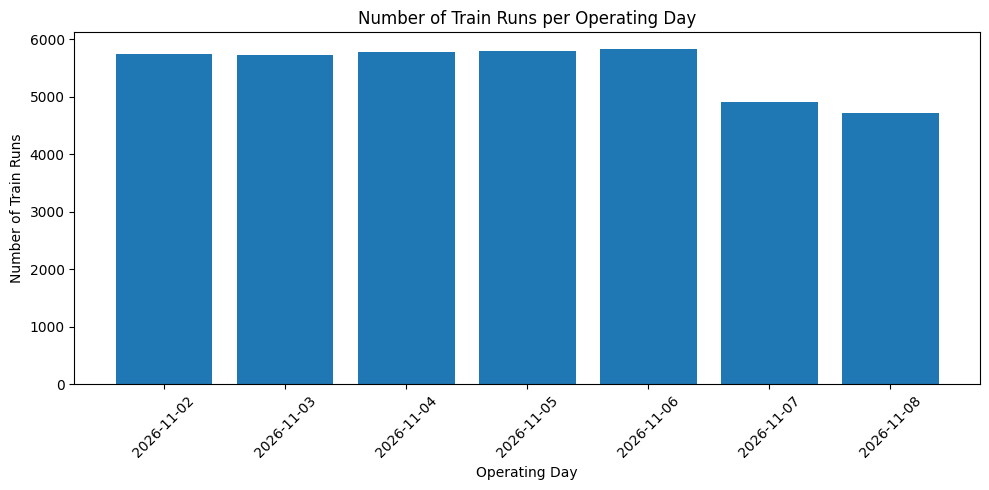

In [7]:
plt.figure(figsize=(10, 5))
plt.bar(daily_summary.index.astype(str), daily_summary["train_runs"])
plt.title("Number of Train Runs per Operating Day")
plt.xlabel("Operating Day")
plt.ylabel("Number of Train Runs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Variable Types

In [8]:
# time columns to datetime
date_cols = [
    "ankunftzeit_soll",
    "ankunftzeit_ist",
    "abfahrtzeit_soll",
    "abfahrtzeit_ist"
]

for col in date_cols:

    # convert to datetime
    parsed = pd.to_datetime(data[col], errors="coerce", utc=True)

    # Show non-null values that could not be converted
    invalid_rows = data[data[col].notna() & parsed.isna()]
    print(f"Invalid values in {col}:")
    print(invalid_rows[[col]])

    data[col] = parsed

Invalid values in ankunftzeit_soll:
Empty DataFrame
Columns: [ankunftzeit_soll]
Index: []
Invalid values in ankunftzeit_ist:
Empty DataFrame
Columns: [ankunftzeit_ist]
Index: []
Invalid values in abfahrtzeit_soll:
Empty DataFrame
Columns: [abfahrtzeit_soll]
Index: []
Invalid values in abfahrtzeit_ist:
Empty DataFrame
Columns: [abfahrtzeit_ist]
Index: []


In [9]:
# date column to datetime
parsed = pd.to_datetime(data["betriebstag"], errors="coerce")

# Show non-null values that could not be converted
invalid_rows = data[data["betriebstag"].notna() & parsed.isna()]
print(invalid_rows[["betriebstag"]])

data["betriebstag"] = parsed

Empty DataFrame
Columns: [betriebstag]
Index: []


In [10]:
# calculate departure and arrival delays in minutes
data["ab_versp_min"] = (
    data["abfahrtzeit_ist"] - data["abfahrtzeit_soll"]
).dt.total_seconds() / 60

data["an_versp_min"] = (
    data["ankunftzeit_ist"] - data["ankunftzeit_soll"]
).dt.total_seconds() / 60

# calculate difference between actual and scheduled journey duration
data["fahrzeit_delta_min"] = pd.to_timedelta(
    data["fahrzeit_delta"], errors="coerce"
).dt.total_seconds() / 60

In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38512 entries, 0 to 38511
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype              
---  ------                --------------  -----              
 0   zugnummer             38512 non-null  int64              
 1   betriebstag           38512 non-null  datetime64[ns]     
 2   abfahrtzeit_soll      38369 non-null  datetime64[ns, UTC]
 3   abfahrtzeit_ist       38345 non-null  datetime64[ns, UTC]
 4   start_betriebsstelle  38512 non-null  object             
 5   ankunftzeit_soll      38255 non-null  datetime64[ns, UTC]
 6   ankunftzeit_ist       38343 non-null  datetime64[ns, UTC]
 7   ziel_betriebsstelle   38512 non-null  object             
 8   fahrzeit_delta        37950 non-null  object             
 9   ab_versp_min          38202 non-null  float64            
 10  an_versp_min          38086 non-null  float64            
 11  fahrzeit_delta_min    37950 non-null  float64            
dtypes: d

## Delays Outlier Detection

In [12]:
delay_summary = pd.DataFrame({
    "metric": ["Observed arrival delays", "Early arrivals", "On-time or early arrivals", "Late arrivals",
               "More than 3 minutes late", "More than 5 minutes late", "More than 10 minutes late", "More than 15 minutes late"],
    "value": [data["an_versp_min"].notna().sum(), (data["an_versp_min"] < 0).sum(), (data["an_versp_min"] <= 0).sum(),
              (data["an_versp_min"] > 0).sum(), (data["an_versp_min"] > 3).sum(), (data["an_versp_min"] > 5).sum(),
              (data["an_versp_min"] > 10).sum(), (data["an_versp_min"] > 15).sum()]
})
delay_summary

,metric,value
0,Observed arrival delays,38086
1,Early arrivals,12484
2,On-time or early arrivals,13301
3,Late arrivals,24785
4,More than 3 minutes late,7026
5,More than 5 minutes late,3947
6,More than 10 minutes late,1560
7,More than 15 minutes late,883


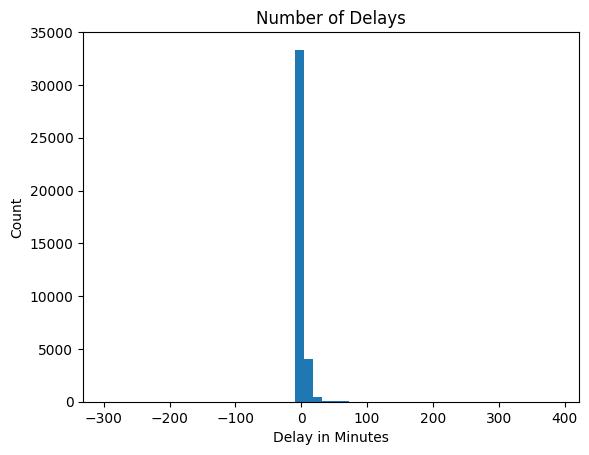

In [13]:
plt.hist(data["an_versp_min"], bins = 50)
plt.title("Number of Delays")
plt.xlabel("Delay in Minutes")
plt.ylabel("Count")
plt.show()

In [28]:
sum(data["an_versp_min"] < -60)

2

In [29]:
sum(data["an_versp_min"] > 60)

54

In [30]:
data[data["an_versp_min"] < -60].sort_values(by="an_versp_min")

,zugnummer,betriebstag,abfahrtzeit_soll,abfahrtzeit_ist,start_betriebsstelle,ankunftzeit_soll,ankunftzeit_ist,ziel_betriebsstelle,fahrzeit_delta,ab_versp_min,an_versp_min,fahrzeit_delta_min
29433,1540,2026-11-07,2026-11-07 03:00:00+00:00,2026-11-06 22:03:05+00:00,SAA,2026-11-07 03:00:00+00:00,2026-11-06 22:03:05+00:00,SAA,00:00:00,-296.916667,-296.916667,0.0
8743,6169,2026-11-03,2026-11-03 12:49:00+00:00,2026-11-03 11:08:54+00:00,SV,2026-11-03 12:49:00+00:00,2026-11-03 11:08:54+00:00,SV,00:00:00,-100.100000,-100.100000,0.0


In [31]:
data[data["an_versp_min"] > 60].sort_values(by="an_versp_min").head()

,zugnummer,betriebstag,abfahrtzeit_soll,abfahrtzeit_ist,start_betriebsstelle,ankunftzeit_soll,ankunftzeit_ist,ziel_betriebsstelle,fahrzeit_delta,ab_versp_min,an_versp_min,fahrzeit_delta_min
21365,15415,2026-11-05,2026-11-05 01:11:28+00:00,2026-11-05 01:14:27+00:00,SBM,2026-11-05 07:32:13+00:00,2026-11-05 08:32:14+00:00,SD G,00:57:02,2.983333,60.016667,57.033333
23113,132,2026-11-06,2026-11-06 16:57:00+00:00,2026-11-06 18:03:21+00:00,TBV,2026-11-06 21:04:48+00:00,2026-11-06 22:05:12+00:00,MLX,-00:05:57,66.350000,60.400000,-5.950000
28997,251,2026-11-07,2026-11-07 12:46:00+00:00,2026-11-07 12:54:30+00:00,BPA,2026-11-07 13:51:42+00:00,2026-11-07 14:52:21+00:00,OF,00:52:09,8.500000,60.650000,52.150000
29004,258,2026-11-07,2026-11-07 04:12:16+00:00,2026-11-07 04:12:22+00:00,OF,2026-11-07 05:09:38+00:00,2026-11-07 06:10:44+00:00,BELG,01:01:00,0.100000,61.100000,61.000000
11489,69,2026-11-04,2026-11-04 15:52:00+00:00,2026-11-04 16:37:41+00:00,MFL,2026-11-04 18:29:34+00:00,2026-11-04 19:30:52+00:00,MLX,00:15:37,45.683333,61.300000,15.616667


When examining the trains that arrived more than an hour ahead of schedule, we can see this is a very rare occurrence here. Whilst arriving at least one hour late gives 54 results.

## Data completeness and cancellations

In [33]:
# missing values in the most relevant time and delay columns
missing_values = data[["ankunftzeit_soll", "ankunftzeit_ist", "abfahrtzeit_soll", "abfahrtzeit_ist",
                       "fahrzeit_delta", "an_versp_min", "ab_versp_min"]].isna().sum()
print(missing_values)

ankunftzeit_soll    257
ankunftzeit_ist     169
abfahrtzeit_soll    143
abfahrtzeit_ist     167
fahrzeit_delta      562
an_versp_min        426
ab_versp_min        310
dtype: int64


In [34]:
# proportion of missing values (in percent)
missing_percentage = (
    data.isna().mean() * 100
).sort_values(ascending=False)

print(missing_percentage)

fahrzeit_delta          1.459285
fahrzeit_delta_min      1.459285
an_versp_min            1.106149
ab_versp_min            0.804944
ankunftzeit_soll        0.667324
ankunftzeit_ist         0.438824
abfahrtzeit_ist         0.433631
abfahrtzeit_soll        0.371313
zugnummer               0.000000
betriebstag             0.000000
ziel_betriebsstelle     0.000000
start_betriebsstelle    0.000000
dtype: float64


## Decide on a subnetwork for the optimisation problem
Before choosing a subnetwork we inspect all unique station codes.

In [35]:
# all unique departure and arrival station codes
departure_stations = set(data["start_betriebsstelle"].unique())
arrival_stations = set(data["ziel_betriebsstelle"].unique())

all_stations = sorted(departure_stations | arrival_stations)

print("Number of unique stations:", len(all_stations))
print(all_stations)

Number of unique stations: 538
['AA', 'AD A1', 'AHO', 'AK', 'AK H1', 'AMOH2', 'AMSS11', 'AMSZ1', 'AOS', 'APOH1', 'ASO', 'AT H1', 'AT S11', 'AT S12', 'AU', 'AU H1', 'AW S42', 'B  G', 'B  H1', 'B  S11', 'BA', 'BC', 'BCHH4', 'BE', 'BEH', 'BEL', 'BELG', 'BF H1', 'BF S21', 'BF S22', 'BG', 'BG H1', 'BGLH2', 'BGTG', 'BIB', 'BK', 'BL', 'BLE', 'BLEG', 'BLS', 'BM', 'BPA', 'BR H3', 'BRD', 'BRF', 'BRO', 'BRU', 'BRUG', 'BS S11', 'BS S12', 'BU', 'BVS', 'BVSH1', 'BZ H1', 'CV', 'DK', 'DNV', 'DO H1', 'DR', 'DRG', 'E', 'EBN', 'EBR', 'EDLA2', 'EDO', 'EGGS11', 'EGGS12', 'EH', 'ENZ', 'ENZH1', 'ERFA2', 'ESU', 'F', 'F  H1', 'F  H1S', 'F  SA1', 'F  SB2', 'F  SD2', 'FAA', 'FAM', 'FB H1', 'FEGH1', 'FELH1', 'FH', 'FI H1', 'FIBH1', 'FK H1', 'FK H1N', 'FK S11', 'FLD', 'FM S11', 'FM S12', 'FPR', 'FR S11', 'FR S12', 'FRS', 'FRT', 'FS H1', 'FUEA1', 'FWE', 'FWSZ1', 'G', 'GA H1', 'GAE', 'GBK', 'GBKH1', 'GD H1', 'GDB', 'GEFS31', 'GEFS32', 'GES', 'GH', 'GKF', 'GL', 'GLD', 'GLDG', 'GLOS21', 'GLOS22', 'GM', 'GM G', 'GMI', 

In [36]:
# most frequently occurring departure stations
print(data["start_betriebsstelle"].value_counts().head(30))

# most frequently occurring arrival stations
print(data["ziel_betriebsstelle"].value_counts().head(30))

start_betriebsstelle
NG        1406
MLX       1128
OF         936
HFG        785
WV         782
OW         751
KLSS22     660
WF H1      628
LZW        604
GZS        601
NBN        582
HF H1      498
WT         443
H  H3      436
HW Z3      390
VBO        388
BU         374
LIR        357
VN H1      336
GKF        336
WO S12     332
NBF        324
B  S11     321
SBM        305
SAH        304
STC        302
SB G       301
AMSZ1      281
GMI        272
UF H1      271
Name: count, dtype: int64
ziel_betriebsstelle
MLX       1182
NG        1174
OF         989
HFG        791
WV         778
OW         687
KLSS21     650
GZS        630
WF H1      614
LZW        599
NBN        557
H  H3      468
WT         449
HW Z3      394
VBO        384
BU         371
LIR        358
GKF        356
LATH1      354
B  H1      330
NBF        330
SB G       322
VN H1      316
SAH        304
STC        301
AMSZ1      299
HF H1      291
SBM        285
UF H1      270
LGF        267
Name: count, dtype: int64
